In [254]:
from sklearn.datasets import make_moons

data = make_moons(n_samples=10000 , 
                  random_state=314159)

X , y = data

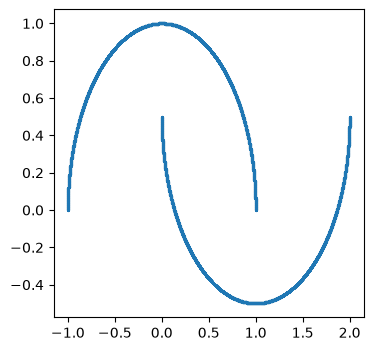

In [255]:
import matplotlib.pyplot as plt 

plt.figure(figsize=(4,4))
plt.scatter(X[: , 0] , X[: , 1], s = 1.5 )

In [256]:
data_min = X.min(axis=0)
data_max = X.max(axis=0)

normalized_data = (X - data_min) / (data_max - data_min)
normalized_data = normalized_data * 2 - 1 




In [257]:
import torch 

In [258]:
from torch.utils.data import DataLoader

x_tensor = torch.tensor(normalized_data , dtype=torch.float32)

data_loader = DataLoader(x_tensor , batch_size= 64 , shuffle= True )

In [259]:
next(iter(data_loader)).shape

torch.Size([64, 2])

beta should increase as t increases , because beta is the coefficient of eps. and as we reach T, we want to have a pure noisy image

In [260]:
device = 'cuda' if torch.cuda.is_available() else 'cpu'

device

'cuda'

In [261]:
T = 1000
betas = torch.linspace(1e-4 , 0.02 , T , device=device)
alphas = 1 - betas 

alpha_bar = torch.cumprod(alphas , 0)
alpha_bar[:10]

tensor([0.9999, 0.9998, 0.9996, 0.9995, 0.9993, 0.9991, 0.9989, 0.9986, 0.9984,
        0.9981], device='cuda:0')

In [262]:
alpha_bar.device

device(type='cuda', index=0)

In [263]:
alpha_bar[2]

tensor(0.9996, device='cuda:0')

In [264]:
def forward_process(x0: torch.Tensor, t):
    # x shape : (bs , 2)

    eps = torch.randn_like(x0 , device = device)

    alpha_bar_t = alpha_bar[t].reshape(-1 , 1)

    mu = torch.sqrt(alpha_bar_t) * x0 
    sigma =  torch.sqrt(1-alpha_bar_t) * eps

    x_t = mu + sigma

    return x_t , eps

In [265]:
import torch.nn as nn

In [266]:
import math

def time_embed(t, dim):
    half_dim = dim // 2

    frequencies = torch.exp(
        -math.log(10000) *
        torch.arange(half_dim, device=t.device).float() / half_dim
    )

    angles = t.float().unsqueeze(1) * frequencies.unsqueeze(0)

    embedding = torch.cat([
        torch.sin(angles),
        torch.cos(angles)
    ], dim=1)

    return embedding

In [267]:

class NoisePredictor(nn.Module):
    def __init__(self, time_dim=32):
        super().__init__()
        self.time_dim = time_dim
        
        self.net = nn.Sequential(
            nn.Linear(2 + time_dim, 128),
            nn.SiLU(),
            nn.Linear(128, 128),
            nn.SiLU(),
            nn.Linear(128, 128),
            nn.SiLU(),
            nn.Linear(128, 2) 
        )

    def forward(self, x, t):
        t_emb = time_embed(t, self.time_dim)
        
        x_input = torch.cat([x, t_emb], dim=-1)
        
        return self.net(x_input)


In [268]:
model = NoisePredictor().to(device=device)

In [269]:
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
loss_fn = nn.MSELoss()

In [275]:
def train_loop(dataloader, model, loss_fn, optimizer):
    model.train()
    for batch,X in enumerate(dataloader):
        X = X.to(device)
        t = torch.randint(0 , T , (X.shape[0],) , device=device)

        X_t , eps = forward_process(X , t)

        eps_pred = model(X_t , t)

        loss = loss_fn(eps , eps_pred)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        if batch % 100 == 0:
            loss= loss.item()
            print(f"loss: {loss:>7f}")

for t in range(30):
    print(f"Epoch {t+1}\n-------------------------------")
    train_loop(data_loader, model, loss_fn, optimizer)
print("Done!")

Epoch 1
-------------------------------
loss: 0.114439
loss: 0.091992
Epoch 2
-------------------------------
loss: 0.131485
loss: 0.079792
Epoch 3
-------------------------------
loss: 0.212736
loss: 0.129037
Epoch 4
-------------------------------
loss: 0.298708
loss: 0.145053
Epoch 5
-------------------------------
loss: 0.160057
loss: 0.219408
Epoch 6
-------------------------------
loss: 0.214112
loss: 0.187073
Epoch 7
-------------------------------
loss: 0.195268
loss: 0.135160
Epoch 8
-------------------------------
loss: 0.151572
loss: 0.275227
Epoch 9
-------------------------------
loss: 0.175568
loss: 0.153646
Epoch 10
-------------------------------
loss: 0.229495
loss: 0.159646
Epoch 11
-------------------------------
loss: 0.140073
loss: 0.133446
Epoch 12
-------------------------------
loss: 0.128719
loss: 0.127983
Epoch 13
-------------------------------
loss: 0.138140
loss: 0.174805
Epoch 14
-------------------------------
loss: 0.136838
loss: 0.184759
Epoch 15
------

In [281]:
@torch.no_grad()
def sample(model):
    model.eval()

    x = torch.randn(700 , 2 , device = device)
    for t in range(T-1 , -1 , -1):


        time = torch.full((700,), t, device=device, dtype=torch.long)
        eps_theta = model(x , time)
        sigma_t = 0 if t == 0 else torch.sqrt(betas[t])


        z = torch.randn_like(x , device = device)

        x = (x - (betas[t] / (torch.sqrt(1-alpha_bar[t])) * eps_theta)) / torch.sqrt(alphas[t]) + sigma_t * z

    return x

(700, 2)

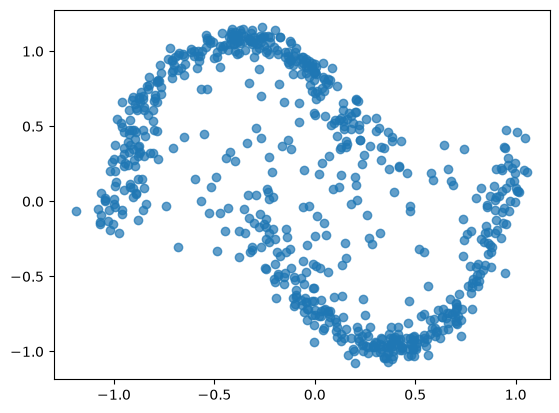

In [282]:
X = sample(model).detach().cpu().numpy()

plt.scatter(X[: , 0] , X[: , 1] , alpha=0.7)
X.shape

In [286]:
import torch
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.animation as animation

@torch.no_grad()
def sample_with_frames(model, num_samples=5000, save_every=20):

    model.eval()

    # شروع از نویز تصادفی
    x = torch.randn(num_samples, 2, device=device)

    frames = []

    # ذخیره فریم اولیه
    frames.append(x.cpu().numpy().copy())

    for time in reversed(range(T)):

        t = torch.full(
            (num_samples,),
            time,
            device=device,
            dtype=torch.long
        )

        # پیش‌بینی نویز
        predicted_noise = model(x, t)

        # محاسبه میانگین توزیع معکوس
        mean = (
            x
            - betas[time] / torch.sqrt(1 - alpha_bar[time])
            * predicted_noise
        ) / torch.sqrt(alphas[time])

        # اضافه کردن نویز تصادفی
        if time > 0:
            x = mean + torch.sqrt(betas[time]) * torch.randn_like(x)
        else:
            x = mean

        # ذخیره فریم
        if time % save_every == 0 or time == 0:
            frames.append(x.cpu().numpy().copy())

    return frames

In [ ]:
frames = sample_with_frames(
    model,
    num_samples=5000,
    save_every=10
)

data_mean = X.mean(axis=0)

data_scale = np.sqrt(
    np.mean((X - data_mean) ** 2)
)

frames = [
    frame * data_scale + data_mean
    for frame in frames
]

fig, ax = plt.subplots(figsize=(8, 8))

scatter = ax.scatter(
    frames[0][:, 0],
    frames[0][:, 1],
    s=3,
    alpha=0.7
)

margin = 0.5
ax.set_xlim(X[:, 0].min() - margin,
            X[:, 0].max() + margin)

ax.set_ylim(X[:, 1].min() - margin,
            X[:, 1].max() + margin)

ax.set_aspect("equal")

title = ax.set_title("Reverse Diffusion")

ax.set_xlabel("X")
ax.set_ylabel("Y")


def update(frame_index):

    points = frames[frame_index]

    scatter.set_offsets(points)

    title.set_text(
        f"Reverse Diffusion | Frame {frame_index + 1}/{len(frames)}"
    )

    return scatter, title


ani = animation.FuncAnimation(
    fig,
    update,
    frames=len(frames),
    interval=100,
    blit=True
)

ani.save(
    "2D_Diffusion.gif",
    writer="pillow",
    fps=12
)

plt.close(fig)

print("GIF saved successfully!")

GIF saved successfully!
